# Redshift distributions of the detected transients

## Overview

This notebook plots the **redshift distribution of each transient type** that UVEX is expected to detect, as the
expected number of real UVEX events per redshift bin, together with the uncertainty on every bin.

It produces two figures:

1. A **combined figure** with every type on one set of axes, so the types can be compared. It comes in three layouts
   (`COMBINED_STYLE`): translucent, overlapping distributions in absolute units; cumulative distributions; or one offset
   row per type with each scaled to its own peak.
2. **One panel per type**, each with its two sources of uncertainty (below), the type's total yield, and upper limits in
   the bins that hold no simulated events.

It also builds a table of every bin, with its counts, expected events and both uncertainty intervals, which it can save
for later use.

### Required data

| Item | Where it comes from | Default |
| --- | --- | --- |
| The event summary table (`event_summary.ecsv`) | the output of a pipeline run (`uvex-transients run ...`), or a release download | the one attached to release `v0.6.5alpha` (8 MB) |

The table has one row per simulated event that survived the pipeline's cuts, with its `redshift` and `weight`. Its
`meta` also carries what the uncertainties need: `n_pre_cut` (how many events were generated, per type),
`expected_events` (how many real events the survey could see, per type) and `rate_ci` (the rate uncertainty, per type).
Set `EVENT_SUMMARY_PATH` to use your own file, or `RELEASE_TAG` to use another release.

### How the numbers and their uncertainties are computed

The pipeline does not simulate every real event. For each type it generates `n` events (the `sampling_factor` thins the
high-rate types), keeps the `k` that pass the cuts, and knows that the survey could see `mu0` real events of that type
in all. So each simulated event stands for `weight = mu0 / n` real ones, and the expected number of real events that pass
the cuts is `mu0 * k / n`. This is the same as summing the `weight` of the surviving events, and it is what
`uvex_transients.simulation.rates.estimate_yield` returns per type.

A redshift bin is the same calculation restricted to the events whose redshift falls in it: if `k` of the `n` generated
events end up selected *and* in that bin, the bin holds `mu0 * k / n` expected events. The two uncertainties are kept
apart, exactly as in `estimate_yield`, because they behave differently:

- **Monte Carlo (statistical).** Which events land in the bin is a finite random sample, so `k` is binomial in `n`. The
  exact Clopper-Pearson interval on `k / n` at confidence `CONFIDENCE`, scaled by `mu0`, is drawn as **black error
  bars**. It stays well behaved where `k` is small, and in a bin with `k = 0` it becomes an **upper limit**, drawn as a
  triangle. It is independent from bin to bin and from type to type.
- **Rate (systematic).** `meta['rate_ci']` holds, per type, a lower and an upper factor on the volumetric event rate,
  and so on `mu0`. Applied to a bin it gives the **pale band**. It scales the whole distribution of a type up or down
  together, so it is fully correlated across the bins of that type, and it is not part of the Monte Carlo interval.

### Caveats

- Types are not summed into a total: their Monte Carlo errors are independent, but their rate uncertainties are shared,
  so adding them would mix the two. (`estimate_yield` does not sum them either.)
- An event outside `REDSHIFT_BINS` is in no bin, so a type's bins can sum to less than its total yield. The notebook
  reports how many events fall outside.
- A selection (`SELECTION`) narrows `k` but not `n`, so the bins are the expected events *that pass the selection*.
- The style cell uses LaTeX for text when a TeX installation is found, and matplotlib's own Computer Modern otherwise.

## Setup and Configuration

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.table import QTable
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import NullFormatter

from uvex_transients.simulation.rates import estimate_yield
from uvex_transients.utils import config, get_results
from uvex_transients.utils.stat_utils import clopper_pearson_interval

[uvex_transients]-INFO: Downsampled a bandpass table from 11000 to 353 points (worst-case 0.00089 mag over 1500-50000 K, mass rescale 0.999041).


[uvex_transients]-INFO: Downsampled a bandpass table from 11000 to 366 points (worst-case 0.00023 mag over 1500-50000 K, mass rescale 0.999667).


In [2]:
# ---------------------------------------------------------------------------------------------- #
# UVEX Transients notebook style. Copy this cell unchanged into every notebook (see the readme), #
# so that all of them look the same.                                                             #
# ---------------------------------------------------------------------------------------------- #
import shutil

import matplotlib as mpl
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap

# The UVEX logo gradient runs from blue (top) to violet (bottom). These are its colors, sampled from the logo files.
UVEX_BLUE = "#72AEFF"
UVEX_VIOLET = "#AF6EFF"
# The same hues, deepened so that thin lines and small markers stay legible on a white background.
UVEX_BLUE_DEEP = "#3B87EB"
UVEX_VIOLET_DEEP = "#9742ED"
UVEX_NAVY = "#0A0B1E"  # A dark background for images and maps.

# Default color cycle: the two logo hues first, then accents that stay apart from them and from each other.
UVEX_CYCLE = [UVEX_BLUE_DEEP, UVEX_VIOLET_DEEP, "#13A89E", "#F2A93B", "#E5509A", "#475569"]

# Sequential colormap for images and maps, "uvex": indigo (low) through violet and blue to pale (high). Its lightness
# rises steadily, so it also reads in grayscale. The low end is lighter than UVEX_NAVY, so faint pixels stay visible.
UVEX_CMAP = LinearSegmentedColormap.from_list("uvex", ["#2A2078", "#4B2BA8", UVEX_VIOLET, UVEX_BLUE, "#EAF4FF"])
mpl.colormaps.register(UVEX_CMAP, name="uvex", force=True)

# Text is set with LaTeX when a TeX installation is found, and with matplotlib's own Computer Modern look-alike if not.
USE_LATEX = shutil.which("latex") is not None and shutil.which("dvipng") is not None

mpl.rcParams.update(
    {
        # --- Publication style (AAS two-column-ish, LaTeX/Computer Modern) ---
        "text.usetex": USE_LATEX,
        "text.latex.preamble": r"\usepackage{amsmath,amssymb}",
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "cmr10", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        "axes.formatter.use_mathtext": True,
        "axes.unicode_minus": False,
        "font.size": 10,
        "axes.labelsize": 10,
        "axes.titlesize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 8,
        "axes.linewidth": 0.6,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 3,
        "xtick.minor.size": 1.5,
        "ytick.major.size": 3,
        "ytick.minor.size": 1.5,
        "lines.linewidth": 1.0,
        "figure.dpi": 150,
        "savefig.dpi": 300,
        # --- UVEX colors ---
        "axes.prop_cycle": cycler(color=UVEX_CYCLE),
        "image.cmap": "uvex",
        "legend.frameon": False,
    }
)


def tex(text):
    """Escape the characters LaTeX treats specially (_ % & #), so plain text can go into labels when LaTeX is on."""
    if mpl.rcParams["text.usetex"]:
        for char in "_%&#":
            text = text.replace(char, "\\" + char)
    return text

In [3]:
# ------------------------------------------------------------------ #
# User settings. Everything you are likely to want to change is here. #
# ------------------------------------------------------------------ #

# --- Data ---
EVENT_SUMMARY_PATH = None  # Path to an event summary file. None: download it from a release.
RELEASE_TAG = "v0.6.5alpha"  # The release to download from. None: the newest, which may not carry the summary.

# --- Selection ---
INCLUDED_TRANSIENTS = None  # List of transient types to show, e.g. ["tde", "slsne"]. None: every type in the table.
SELECTION = None  # A function of the table that returns a boolean mask, e.g. lambda t: t["n_det"] >= 5. None: all rows.

# --- Redshift bins and uncertainties ---
REDSHIFT_BINS = np.linspace(
    0, 2, 30
)  # Bin edges. Low-redshift types (the SNe) fill only a few bins, so finer bins help.
CONFIDENCE = None  # Confidence level of the Monte Carlo interval. None: the package default.
SHOW_RATE_BAND = True  # Draw the rate uncertainty as a pale band.

# --- Appearance ---
TYPE_LABELS = {
    "ia_sne": "SNe Ia",
    "iip_sne": "SNe IIP",
    "iib_sne": "SNe IIb",
    "ib_sne": "SNe Ib",
    "ic_sne": "SNe Ic",
    "icbl_sne": "SNe Ic-BL",
    "slsne": "SLSNe",
    "tde": "TDEs",
    "lfbot": "LFBOTs",
    "llgrb": "llGRBs",
    "kilonova": "Kilonovae",
}
# The supernovae run along the logo gradient, blue to violet. The other classes take the accents of the default cycle.
SN_ORDER = ["ia_sne", "iip_sne", "iib_sne", "ib_sne", "ic_sne", "icbl_sne", "slsne"]
_gradient = LinearSegmentedColormap.from_list("sne", [UVEX_BLUE_DEEP, UVEX_VIOLET_DEEP])(
    np.linspace(0, 1, len(SN_ORDER))
)
TYPE_COLORS = {name: mpl.colors.to_hex(color) for name, color in zip(SN_ORDER, _gradient)}
TYPE_COLORS |= {"tde": UVEX_CYCLE[2], "lfbot": UVEX_CYCLE[3], "llgrb": UVEX_CYCLE[4], "kilonova": UVEX_CYCLE[5]}
TYPE_LINESTYLES = {
    name: ["-", "--", "-.", ":"][i % 4] for i, name in enumerate(SN_ORDER)
}  # Tells similar SN colors apart.
# COMBINED_STYLE: "layered" overlaps translucent distributions in absolute units, "cumulative" plots the fraction of
#                 each type's events below each redshift, and "ridgeline" gives each type its own row.
COMBINED_STYLE = "layered"
LINE_WIDTH = 1.8  # Line width of the distributions in the combined figure.
FILL_ALPHA = 0.22  # Opacity of the shading under each distribution. The outlines are always opaque.
FILL_DEPTH = None  # Layered figure: decades below each distribution that are shaded. None: all the way down.
N_COLUMNS = 3  # Columns of the per-type figure.
TRIM_PANELS = True  # Trim each per-type panel to the redshifts where it has events.
FIG_WIDTH = 7.5  # Figure width in inches (full page width).

# --- Output ---
OUTPUT_DIR = Path("../../results")  # Repo-level results/ (gitignored). Where figures and the table are written.
SAVE_FIGURES = True  # Write the figures to disk.
SAVE_TABLE = True  # Write the table of every bin to disk.

In [4]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def type_label(name):
    """Return the display label of a transient type."""
    return TYPE_LABELS.get(name, tex(name))


def type_color(name):
    """Return the color of a transient type."""
    return TYPE_COLORS.get(name, "0.4")

## Data Loading

Only the event summary is downloaded (a release also carries a much larger photometry table, which is not needed here).

In [5]:
if EVENT_SUMMARY_PATH is None:
    EVENT_SUMMARY_PATH = get_results(["summary"], tag=RELEASE_TAG)["summary"]
event_summary = QTable.read(EVENT_SUMMARY_PATH)

missing = [key for key in ("n_pre_cut", "expected_events", "rate_ci") if key not in event_summary.meta]
if missing:
    raise ValueError(f"The table's meta has no {missing}; it must come from run_event_summary_action.")

print(f"{len(event_summary)} events of {len(event_summary.meta['n_pre_cut'])} types, from {EVENT_SUMMARY_PATH}.")

[uvex_transients]-INFO: Querying https://api.github.com/repos/TransientsExtragalactic/uvex-transients/releases for the release list.


[uvex_transients]-INFO: Results asset event_summary.ecsv already present at /Users/ediggins/Library/Caches/uvex_transients/results/v0.6.5alpha/event_summary.ecsv.


12291 events of 11 types, from /Users/ediggins/Library/Caches/uvex_transients/results/v0.6.5alpha/event_summary.ecsv.


## Data Processing

For every transient type and every redshift bin: the number `k` of selected events, the expected number of real events
`mu0 * k / n`, the Monte Carlo interval from the Clopper-Pearson interval on `k / n`, and the rate interval from the
type's rate factors. Everything comes from the table's `meta`, as in `estimate_yield`.

In [6]:
confidence = float(config["simulation.default_confidence"] if CONFIDENCE is None else CONFIDENCE)
meta = event_summary.meta

mask = (
    np.ones(len(event_summary), dtype=bool) if SELECTION is None else np.asarray(SELECTION(event_summary), dtype=bool)
)
event_type = np.asarray(event_summary["transient_type"]).astype(str)
redshift = np.asarray(event_summary["redshift"], dtype=float)
weight = np.asarray(event_summary["weight"], dtype=float)
types = sorted(set(event_type)) if INCLUDED_TRANSIENTS is None else list(INCLUDED_TRANSIENTS)
edges = np.asarray(REDSHIFT_BINS, dtype=float)

columns = {name: [] for name in ("transient_type", "z_lower", "z_upper", "n_selected", "expected")}
columns |= {name: [] for name in ("mc_lower", "mc_upper", "rate_lower", "rate_upper")}
for name in types:
    n = int(meta["n_pre_cut"][name])  # Events generated, however many were later cut.
    mu0 = float(meta["expected_events"][name])  # Real events the survey could see.
    rate_lower, rate_upper = (float(factor) for factor in meta["rate_ci"][name])

    in_type = mask & (event_type == name)
    k, _ = np.histogram(redshift[in_type], bins=edges)
    expected = mu0 * k / n

    # Each event stands for mu0 / n real ones, so summing the weights in a bin must give the same number.
    by_weight, _ = np.histogram(redshift[in_type], bins=edges, weights=weight[in_type])
    if not np.allclose(by_weight, expected):
        raise ValueError(f"{name}: the summed weights disagree with mu0 * k / n; is this an event summary table?")

    # The Monte Carlo interval moves k / n at fixed mu0. The rate interval rescales mu0 at fixed k / n.
    fraction_lower, fraction_upper = np.array([clopper_pearson_interval(int(ki), n, confidence) for ki in k]).T
    columns["transient_type"] += [name] * k.size
    columns["z_lower"] += list(edges[:-1])
    columns["z_upper"] += list(edges[1:])
    columns["n_selected"] += list(k)
    columns["expected"] += list(expected)
    columns["mc_lower"] += list(mu0 * fraction_lower)
    columns["mc_upper"] += list(mu0 * fraction_upper)
    columns["rate_lower"] += list(expected * rate_lower)
    columns["rate_upper"] += list(expected * rate_upper)

    outside = int(in_type.sum() - k.sum())
    if outside:
        print(f"{name}: {outside} of {int(in_type.sum())} events lie outside the redshift bins.")

distributions = QTable(columns)
distributions.meta["confidence"] = confidence
if SAVE_TABLE:
    distributions.write(OUTPUT_DIR / "redshift_distributions.ecsv", overwrite=True)
print(f"{len(distributions)} bins ({len(edges) - 1} per type). Monte Carlo confidence: {confidence:.0%}.")

319 bins (29 per type). Monte Carlo confidence: 90%.


The same quantities for each type as a whole, straight from `estimate_yield`. A type's bins sum to its
`expected_events`, less the events that fall outside the redshift bins.

In [7]:
yields = estimate_yield(event_summary, mask=mask, transient_types=types)
yields[
    "transient_type",
    "n_pre_cut",
    "n_selected",
    "expected_events",
    "expected_events_binom_lower",
    "expected_events_binom_upper",
    "expected_events_rate_lower",
    "expected_events_rate_upper",
]

transient_type,n_pre_cut,n_selected,expected_events,expected_events_binom_lower,expected_events_binom_upper,expected_events_rate_lower,expected_events_rate_upper
str8,int64,int64,float64,float64,float64,float64,float64
ia_sne,8358,174,3547.5904947107797,3120.884753547423,4017.270090490344,3274.6989181945655,3820.4820712269934
ib_sne,2678,18,349.71245579916314,226.26373651915353,517.7382976748464,183.96785406921998,507.0812981620811
ic_sne,1196,12,238.65233837570582,137.94216632298682,385.4645327322302,111.90112929989958,360.33030273219646
icbl_sne,730,9,183.09077604173555,95.73423531340063,318.03088457640536,0.0,337.82887197544835
iib_sne,188496,414,16556.68831470711,15242.651939020654,17957.41753229768,8639.485024707084,24081.05447845742
iip_sne,221247,2616,262135.21565476208,253809.93927987808,270671.14726796723,174309.436793878,339671.51154429326
kilonova,588,1,0.09239876386457983,0.004739230283138428,0.43693424791767504,0.02351968534734759,0.25367660624639193
lfbot,11618,1961,193.95209074858062,187.405525779171,200.6399845856528,17.455688167372255,242.44011343572578
llgrb,14063,906,898.829625445928,851.7573505624184,947.773038442967,156.3181957297266,2813.727523135079


## Visualization

### Combined figure

Every type on one set of axes. The three layouts answer different questions:

- **`"layered"`** keeps absolute units: each type is a thick outline on a log axis with a translucent fill under it, so
  where distributions overlap every one stays visible. The types are layered from the tallest distribution at the back
  to the smallest in front, with all the outlines on top. The legend is in the order of total yield and gives each
  type's total.
- **`"cumulative"`** plots, for each type, the fraction of its events below each redshift. There are no overlapping
  bars, so every curve can be traced, and the curves compare *where in redshift* the types are found: a curve that
  rises early is a nearby population, and the dotted line marks the median. It uses the events inside `REDSHIFT_BINS`.
- **`"ridgeline"`** gives each type its own row, ordered by median redshift, with every distribution scaled to its own
  peak. The totals are printed at the end of each row.

The uncertainties are in the per-type figure below.

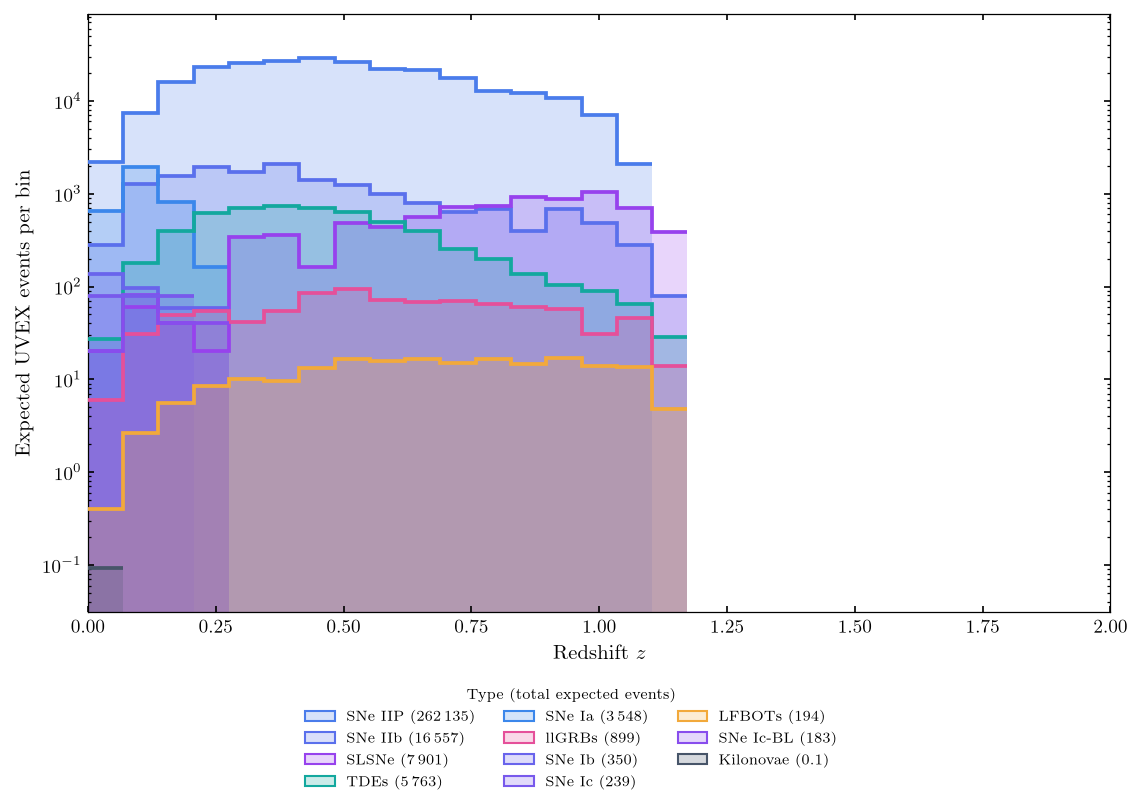

In [8]:
yield_of = {str(row["transient_type"]): row for row in yields}
types_by_yield = sorted(types, key=lambda name: -float(yield_of[name]["expected_events"]))


def bins_of(name):
    """Return the rows of the bin table of one transient type."""
    return distributions[np.asarray(distributions["transient_type"]) == name]


def fmt_count(value):
    """Format an expected number of events for a label: whole numbers when large, one decimal when small."""
    return f"{value:,.0f}".replace(",", r"\,") if value >= 10 else f"{value:.1f}"


def runs(mask):
    """Return the (start, stop) bin ranges of the consecutive True entries of a boolean mask."""
    changes = np.flatnonzero(np.diff(np.concatenate([[False], mask, [False]]).astype(int)))
    return list(zip(changes[::2], changes[1::2]))


def draw_layered(ax):
    """Draw every type as an outline with a translucent band under it on a log axis, and add the legend below."""
    expected = {name: np.asarray(bins_of(name)["expected"], dtype=float) for name in types}
    positive = np.concatenate([values[values > 0] for values in expected.values()])
    floor = positive.min() / 3
    for name in sorted(types, key=lambda n: -expected[n].max()):  # Tallest first, so it sits at the back.
        color = type_color(name)
        for start, stop in runs(expected[name] > 0):
            heights, run_edges = expected[name][start:stop], edges[start : stop + 1]
            depth = floor if FILL_DEPTH is None else np.maximum(heights / 10**FILL_DEPTH, floor)
            ax.stairs(heights, run_edges, baseline=depth, fill=True, color=color, alpha=FILL_ALPHA, lw=0, zorder=1)
            ax.stairs(heights, run_edges, baseline=None, color=color, lw=LINE_WIDTH, zorder=3)
    ax.set_yscale("log")
    ax.set_ylim(floor, positive.max() * 3)
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel(r"Redshift $z$")
    ax.set_ylabel("Expected UVEX events per bin")
    ax.get_figure().legend(
        handles=[
            Patch(
                facecolor=mpl.colors.to_rgba(type_color(name), FILL_ALPHA),
                edgecolor=type_color(name),
                lw=1.0,
                label=rf"{type_label(name)} (${fmt_count(float(yield_of[name]['expected_events']))}$)",
            )
            for name in types_by_yield
        ],
        title="Type (total expected events)",
        title_fontsize=7,
        ncol=3,
        loc="outside lower center",
        fontsize=7,
    )


def draw_ridgeline(ax, overlap=1.8):
    """Draw one shaded row per type, ordered by median redshift and scaled to its own peak, overlapping the next."""
    expected = {name: np.asarray(bins_of(name)["expected"], dtype=float) for name in types}
    median = {name: edges[1:][np.searchsorted(np.cumsum(v), np.sum(v) / 2)] for name, v in expected.items()}
    order = sorted(types, key=lambda name: median[name])  # The lowest median redshift at the bottom.
    for row, name in enumerate(order):
        color = type_color(name)
        top = row + expected[name] / expected[name].max() * overlap  # Absolute heights: stairs() takes positions.
        z = 3 * (len(order) - row)  # Rows higher up sit further back, so each row overlaps the one above it.
        ax.axhline(row, color=color, lw=0.5, alpha=0.6, zorder=z)
        ax.stairs(top, edges, baseline=row, fill=True, color=color, alpha=FILL_ALPHA + 0.15, lw=0, zorder=z + 1)
        ax.stairs(np.where(top > row, top, np.nan), edges, baseline=None, color=color, lw=LINE_WIDTH, zorder=z + 2)
        ax.text(
            edges[-1],
            row + 0.08,
            rf"$N = {fmt_count(float(yield_of[name]['expected_events']))}$",
            ha="right",
            va="bottom",
            fontsize=7,
            color="0.3",
            zorder=z + 2.9,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.6, "alpha": 0.85},
        )
    ax.set_yticks(range(len(order)), [type_label(name) for name in order])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.2, len(order) - 1 + overlap + 0.1)
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel(r"Redshift $z$")
    ax.set_title("Each distribution is scaled to its own peak", loc="left", fontsize=8)


def draw_cumulative(ax):
    """Draw, for every type, the fraction of its events below each redshift, and add the legend below."""
    for name in types_by_yield:
        expected = np.asarray(bins_of(name)["expected"], dtype=float)
        cumulative = np.concatenate([[0.0], np.cumsum(expected)]) / expected.sum()
        ax.plot(
            edges,
            cumulative,
            color=type_color(name),
            ls=TYPE_LINESTYLES.get(name, "-"),
            lw=LINE_WIDTH,
            label=rf"{type_label(name)} (${fmt_count(float(yield_of[name]['expected_events']))}$)",
        )
    ax.axhline(0.5, color="0.6", lw=0.6, ls=":", zorder=0)
    ax.text(edges[-1], 0.51, "median", ha="right", va="bottom", fontsize=7, color="0.45")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_ylim(0, 1.02)
    ax.set_xlabel(r"Redshift $z$")
    ax.set_ylabel("Cumulative fraction of events")
    handles, labels = ax.get_legend_handles_labels()
    ax.get_figure().legend(
        handles,
        labels,
        title="Type (total expected events)",
        title_fontsize=7,
        ncol=3,
        loc="outside lower center",
        fontsize=7,
    )


if COMBINED_STYLE == "layered":
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 0.7 * FIG_WIDTH), layout="constrained")
    draw_layered(ax)
elif COMBINED_STYLE == "cumulative":
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 0.7 * FIG_WIDTH), layout="constrained")
    draw_cumulative(ax)
elif COMBINED_STYLE == "ridgeline":
    fig, ax = plt.subplots(figsize=(FIG_WIDTH, 0.55 * FIG_WIDTH + 0.25 * len(types)), layout="constrained")
    draw_ridgeline(ax)
else:
    raise ValueError(f"COMBINED_STYLE must be 'layered', 'cumulative' or 'ridgeline', not {COMBINED_STYLE!r}.")
if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / f"redshift_distributions_{COMBINED_STYLE}.png", bbox_inches="tight")
plt.show()

### One panel per type

Each panel shows the expected events per bin as a step line. The **black error bars** are the Monte Carlo interval, the
**pale band** is the rate uncertainty, and the **open triangles** are the upper limits in bins that hold no simulated
events. The label gives the type's total yield with its Monte Carlo interval. Each panel has its own vertical scale,
since the yields differ by orders of magnitude.

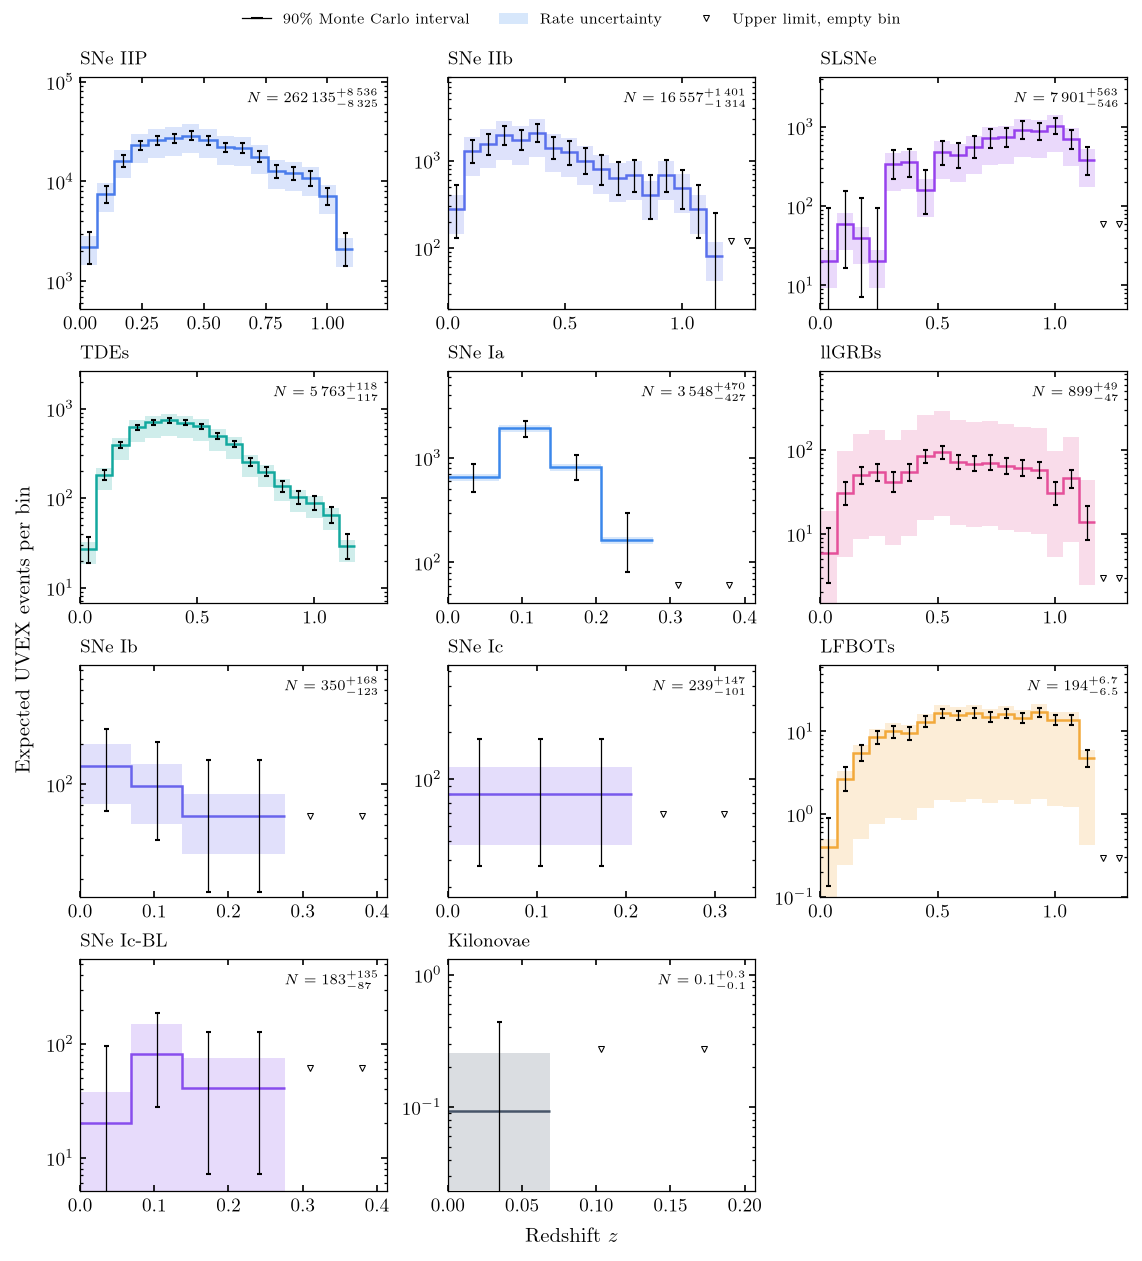

In [9]:
def draw_panel(ax, name):
    """Draw the distribution of one transient type, with both uncertainties, onto `ax`."""
    rows = bins_of(name)
    k = np.asarray(rows["n_selected"])
    expected, mc_lower, mc_upper = (np.asarray(rows[col], dtype=float) for col in ("expected", "mc_lower", "mc_upper"))
    rate_lower, rate_upper = (np.asarray(rows[col], dtype=float) for col in ("rate_lower", "rate_upper"))
    color = type_color(name)
    left, width = edges[:-1], np.diff(edges)
    filled, empty = k > 0, k == 0

    # A vertical range with room below the faintest bin, and room for the upper limits of empty bins.
    floor = expected[filled].min() / 4 if filled.any() else mc_upper[empty].min() / 4
    ceiling = max(mc_upper.max(), rate_upper.max()) * 3
    floor = min(floor, ceiling / 10**1.5)  # At least 1.5 decades, so that the log axis has labeled ticks.
    ax.set_yscale("log")
    ax.set_ylim(floor, ceiling)
    ax.yaxis.set_minor_formatter(NullFormatter())

    if SHOW_RATE_BAND and filled.any():
        lower = np.maximum(rate_lower[filled], floor / 10)  # A lower factor of 0 reaches the bottom of the axes.
        ax.bar(
            left[filled],
            rate_upper[filled] - lower,
            bottom=lower,
            width=width[filled],
            align="edge",
            color=color,
            alpha=0.2,
            lw=0,
            zorder=1,
        )
    ax.stairs(np.where(filled, expected, np.nan), edges, baseline=None, color=color, lw=1.2, zorder=2)
    centers = left + width / 2
    ax.errorbar(
        centers[filled],
        expected[filled],
        yerr=[expected[filled] - mc_lower[filled], mc_upper[filled] - expected[filled]],
        fmt="none",
        ecolor="k",
        elinewidth=0.6,
        capsize=1.2,
        zorder=3,
    )
    ax.plot(
        centers[empty], mc_upper[empty], marker="v", ms=2.5, mfc="none", mec="k", mew=0.5, linestyle="none", zorder=3
    )

    total = yield_of[name]
    value, upper, lower_total = (
        float(total[col]) for col in ("expected_events", "expected_events_binom_upper", "expected_events_binom_lower")
    )
    ax.text(
        0.97,
        0.95,
        rf"$N = {fmt_count(value)}^{{+{fmt_count(upper - value)}}}_{{-{fmt_count(value - lower_total)}}}$",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=7,
    )
    ax.set_title(type_label(name), loc="left", fontsize=9)

    right = edges[-1]
    if TRIM_PANELS and filled.any():
        right = min(edges[-1], edges[np.flatnonzero(filled).max() + 1] + 2 * width[0])
    ax.set_xlim(edges[0], right)


n_rows = int(np.ceil(len(types_by_yield) / N_COLUMNS))
fig, axes = plt.subplots(
    n_rows, N_COLUMNS, figsize=(FIG_WIDTH, 1.9 * n_rows + 0.7), squeeze=False, layout="constrained"
)
for ax, name in zip(axes.flat, types_by_yield):
    draw_panel(ax, name)
for ax in axes.flat[len(types_by_yield) :]:
    ax.axis("off")

legend_handles = [
    Line2D([], [], color="k", lw=0.6, marker="_", label=tex(f"{confidence:.0%} Monte Carlo interval")),
    Patch(color=UVEX_BLUE_DEEP, alpha=0.2, lw=0, label="Rate uncertainty"),
    Line2D([], [], marker="v", ms=3, mfc="none", mec="k", mew=0.5, linestyle="none", label="Upper limit, empty bin"),
]
fig.legend(handles=legend_handles, loc="outside upper center", ncol=3, fontsize=7)
fig.supxlabel(r"Redshift $z$", fontsize=10)
fig.supylabel("Expected UVEX events per bin", fontsize=10)
if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "redshift_distributions_by_type.png", bbox_inches="tight")
plt.show()